# The Anatomy of a Hit: Decoding Audio Features of Global Chart-Toppers
## Member 4 — Artists and Track Characteristics Analysis

**Student contribution:** Artist frequency, track duration, artist-level track counts and average popularity, plus data-quality checks.

**Dataset:** [Spotify Tracks Dataset on Kaggle](https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset)

**Tools:** Python, Pandas, Matplotlib, Google Colab and Markdown. **No machine-learning models are used.**

### Research questions
1. Which artists appear most frequently in this dataset?
2. How are track durations distributed, and are there unusually long or invalid values?
3. Among frequently appearing artists, how do track counts and average popularity compare?
4. How can collaborations be counted without treating a multi-artist track as just one artist?
5. What duplicate or missing-data issues should be disclosed?


## 1. Import libraries

We use Pandas for data preparation and summaries, NumPy for row identifiers, and Matplotlib for visualizations. These are standard exploratory data-analysis tools.

In [3]:
import ast
import io
import re
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload and load the dataset



In [4]:
from google.colab import files

uploaded = files.upload()
if not uploaded:
    raise ValueError("No file was uploaded. Run this cell again and select your Spotify dataset CSV or ZIP file.")

uploaded_names = list(uploaded.keys())
selected_name = uploaded_names[0]
selected_bytes = uploaded[selected_name]

if selected_name.lower().endswith(".csv"):
    df_raw = pd.read_csv(io.BytesIO(selected_bytes), low_memory=False)
    source_file_name = selected_name
elif selected_name.lower().endswith(".zip"):
    with zipfile.ZipFile(io.BytesIO(selected_bytes)) as archive:
        csv_files = [name for name in archive.namelist() if name.lower().endswith(".csv") and not name.endswith("/")]
        if not csv_files:
            raise ValueError("The ZIP file does not contain a CSV file. Extract it and upload the correct CSV.")
        # Prefer a CSV whose filename contains 'spotify'; otherwise select the largest CSV in the archive.
        spotify_candidates = [name for name in csv_files if "spotify" in Path(name).name.lower()]
        candidates = spotify_candidates if spotify_candidates else csv_files
        chosen_csv = max(candidates, key=lambda name: archive.getinfo(name).file_size)
        with archive.open(chosen_csv) as csv_stream:
            df_raw = pd.read_csv(csv_stream, low_memory=False)
        source_file_name = chosen_csv
else:
    raise ValueError("Please upload a .csv file or a .zip archive containing a CSV.")

print(f"Loaded file: {source_file_name}")
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]:,}")
display(df_raw.head())

Saving spotify-tracks-dataset.csv to spotify-tracks-dataset (1).csv
Loaded file: spotify-tracks-dataset (1).csv
Rows: 114,000 | Columns: 22


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 3. Inspecting the columns and check the dataset

The analysis expects the columns `artists` and `duration_ms`. The `track_id`, `track_name`, and `popularity` columns are used where available. The code standardizes column labels and removes typical exported index columns such as `Unnamed: 0`.

In [5]:
# Standardizing column names: e.g. 'Track Name' becomes 'track_name'.
def standardize_column_name(column):
    name = str(column).strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return name.strip("_")

original_columns = list(df_raw.columns)
df = df_raw.copy()
df.columns = [standardize_column_name(column) for column in df.columns]

# Removing exported index columns, if present.
index_columns = [column for column in df.columns if column.startswith("unnamed") or column in {"index", "level_0"}]
if index_columns:
    df = df.drop(columns=index_columns)

# Handling common alternatives for the artist field.
column_aliases = {
    "artist": "artists",
    "artist_name": "artists",
    "song_name": "track_name",
    "track": "track_name",
}
for old_name, new_name in column_aliases.items():
    if old_name in df.columns and new_name not in df.columns:
        df = df.rename(columns={old_name: new_name})

required_columns = ["artists", "duration_ms"]
missing_required = [column for column in required_columns if column not in df.columns]
if missing_required:
    raise ValueError(
        f"Required column(s) not found: {missing_required}. Available columns are: {list(df.columns)}. "
        "Check that you uploaded the correct Spotify Tracks Dataset CSV."
    )

print("Column names in the loaded dataset:")
print(list(df.columns))
print("\nDataset information:")
display(df.info())
print("\nMissing values in the first 20 columns:")
display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing_values"))

Column names in the loaded dataset:
['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  object 
 1   artists           113999 non-null  object 
 2   album_name        113999 non-null  object 
 3   track_name        113999 non-null  object 
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  i

None


Missing values in the first 20 columns:


,missing_values
artists,1
album_name,1
track_name,1
track_id,0
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0
key,0


## 4. Cleaning the relevant fields

Cleaning decisions:
- Droping only rows that are exact duplicates across all retained columns.
- Converting duration and popularity to numeric values where possible.
- Excluding missing or non-positive durations from duration statistics and duration plots.


In [6]:
raw_row_count = len(df_raw)
rows_before_exact_deduplication = len(df)
df = df.drop_duplicates().reset_index(drop=True)
exact_duplicate_rows_removed = rows_before_exact_deduplication - len(df)

# Converting numeric fields
df["duration_ms"] = pd.to_numeric(df["duration_ms"], errors="coerce")
if "popularity" in df.columns:
    df["popularity"] = pd.to_numeric(df["popularity"], errors="coerce")

# Adding stable row identifier for records that do not have a track ID.
df["_record_id"] = np.arange(len(df))
df["duration_minutes"] = df["duration_ms"] / 60000  # millisecs into mins

valid_duration_mask = df["duration_ms"].notna() & (df["duration_ms"] > 0)
duration_data = df.loc[valid_duration_mask].copy()
invalid_duration_rows = int((~valid_duration_mask).sum())
# Invalid durations are excluded from duration summaries and artist mean-duration calculations.
df.loc[~valid_duration_mask, "duration_minutes"] = np.nan

if duration_data.empty:
    raise ValueError("No valid positive track durations were found. Inspect the duration_ms column and uploaded file.")

if "track_id" in df.columns:
    track_id_series = df["track_id"].astype("string").str.strip()
    usable_track_id = track_id_series.notna() & track_id_series.ne("") & track_id_series.str.lower().ne("nan")
    unique_track_ids = int(track_id_series[usable_track_id].nunique())
    duplicate_track_id_rows = int(track_id_series[usable_track_id].duplicated().sum())
else:
    unique_track_ids = None
    duplicate_track_id_rows = None

print(f"Original uploaded rows: {raw_row_count:,}")
print(f"Rows after removing exact duplicates: {len(df):,}")
print(f"Exact duplicate rows removed: {exact_duplicate_rows_removed:,}")
print(f"Rows with missing/non-positive duration: {invalid_duration_rows:,}")
print(f"Rows available for duration analysis: {len(duration_data):,}")
if unique_track_ids is not None:
    print(f"Unique non-missing track IDs: {unique_track_ids:,}")
    print(f"Repeated track-ID rows after exact duplicate removal: {duplicate_track_id_rows:,}")

# Preview of cleaned records used for duration analysis.
display(duration_data[[c for c in ["track_name", "artists", "duration_ms", "duration_minutes", "popularity", "track_id"] if c in duration_data.columns]].head())

Original uploaded rows: 114,000
Rows after removing exact duplicates: 113,550
Exact duplicate rows removed: 450
Rows with missing/non-positive duration: 1
Rows available for duration analysis: 113,549
Unique non-missing track IDs: 89,741
Repeated track-ID rows after exact duplicate removal: 23,809


,track_name,artists,duration_ms,duration_minutes,popularity,track_id
0,Comedy,Gen Hoshino,230666,3.844433,73,5SuOikwiRyPMVoIQDJUgSV
1,Ghost - Acoustic,Ben Woodward,149610,2.493500,55,4qPNDBW1i3p13qLCt0Ki3A
2,To Begin Again,Ingrid Michaelson;ZAYN,210826,3.513767,57,1iJBSr7s7jYXzM8EGcbK5b
3,Can't Help Falling In Love,Kina Grannis,201933,3.365550,71,6lfxq3CG4xtTiEg7opyCyx
4,Hold On,Chord Overstreet,198853,3.314217,82,5vjLSffimiIP26QG5WcN2K


## 5. Parse artist credits carefully

Some CSV files store multiple artists as a list-like string, for example `['Artist A', 'Artist B']`. The parser first attempts to read list-like values safely. It also understands semicolon- or pipe-separated names. If a plain field is ambiguous, it is kept as one name rather than splitting on every comma, because some artist names themselves contain commas.

For artist frequency, a collaboration contributes one credited track to **each** named artist. When `track_id` is available, the same artist-track ID pair is counted once, preventing repeated rows for the same credited track from inflating artist frequency.

In [7]:
def parse_artist_field(value):
    """Return a list of artist names from a Spotify artist field."""
    if value is None or (not isinstance(value, (list, tuple, set)) and pd.isna(value)):
        return []

    if isinstance(value, (list, tuple, set)):
        values = list(value)
    else:
        text = str(value).strip()
        if not text:
            return []

        if text.startswith("[") and text.endswith("]"):
            try:
                parsed = ast.literal_eval(text)
                values = list(parsed) if isinstance(parsed, (list, tuple, set)) else [parsed]
            except (ValueError, SyntaxError):
                # Fallback for a malformed list-like string with quoted names.
                inner = text[1:-1].strip()
                values = [part.strip().strip("'").strip('"') for part in inner.split(",")]
        elif ";" in text:
            values = text.split(";")
        elif "|" in text:
            values = text.split("|")
        else:
            # Avoid splitting plain text on commas, since a name may contain a comma.
            values = [text]

    cleaned = []
    seen = set()
    for item in values:
        if item is None:
            continue
        name = str(item).strip().strip("'\"").strip()
        if not name or name.lower() in {"nan", "none", "null"}:
            continue
        key = name.casefold()
        if key not in seen:
            cleaned.append(name)
            seen.add(key)
    return cleaned


df["_artist_list"] = df["artists"].apply(parse_artist_field)
records_with_artist = int(df["_artist_list"].map(len).gt(0).sum())
records_with_multiple_artists = int(df["_artist_list"].map(len).gt(1).sum())
missing_artist_rows = int(df["_artist_list"].map(len).eq(0).sum())

print(f"Rows with at least one parsed artist: {records_with_artist:,}")
print(f"Rows with multiple parsed artists: {records_with_multiple_artists:,}")
print(f"Rows with no usable artist name: {missing_artist_rows:,}")
print("Examples of source field and parsed artist list:")
display(df[["artists", "_artist_list"]].head(10))

Rows with at least one parsed artist: 113,549
Rows with multiple parsed artists: 29,894
Rows with no usable artist name: 1
Examples of source field and parsed artist list:


,artists,_artist_list
0,Gen Hoshino,[Gen Hoshino]
1,Ben Woodward,[Ben Woodward]
2,Ingrid Michaelson;ZAYN,"[Ingrid Michaelson, ZAYN]"
3,Kina Grannis,[Kina Grannis]
4,Chord Overstreet,[Chord Overstreet]
5,Tyrone Wells,[Tyrone Wells]
6,A Great Big World;Christina Aguilera,"[A Great Big World, Christina Aguilera]"
7,Jason Mraz,[Jason Mraz]
8,Jason Mraz;Colbie Caillat,"[Jason Mraz, Colbie Caillat]"
9,Ross Copperman,[Ross Copperman]


## 6. Artist frequency and artist-level summaries

The main measure is the number of distinct track credits per artist. If an ID is absent for a row, the notebook uses that row's identifier as a fallback. Where available, average/median popularity and average duration are descriptive summaries; popularity is not a measure of artistic quality.

In [8]:
credit_columns = ["_record_id", "_artist_list"]
for column in ["track_id", "track_name", "popularity", "duration_ms", "duration_minutes"]:
    if column in df.columns and column not in credit_columns:
        credit_columns.append(column)

artist_credits = df[credit_columns].explode("_artist_list").rename(columns={"_artist_list": "artist"}).copy()
artist_credits["artist"] = artist_credits["artist"].astype("string").str.strip()
artist_credits = artist_credits.loc[artist_credits["artist"].notna() & artist_credits["artist"].ne("")].copy()
artist_credits["artist_key"] = artist_credits["artist"].str.casefold()

if "track_id" in artist_credits.columns:
    track_ids = artist_credits["track_id"].astype("string").str.strip()
    usable_ids = track_ids.notna() & track_ids.ne("") & track_ids.str.lower().ne("nan")
    artist_credits["_artist_track_key"] = "row:" + artist_credits["_record_id"].astype(str)
    artist_credits.loc[usable_ids, "_artist_track_key"] = "id:" + track_ids.loc[usable_ids].astype(str)
else:
    artist_credits["_artist_track_key"] = "row:" + artist_credits["_record_id"].astype(str)

# Using the most common display spelling while grouping case-insensitively.
def preferred_spelling(series):
    modes = series.mode()
    return modes.iloc[0] if not modes.empty else series.iloc[0]

artist_credits = artist_credits.drop_duplicates(subset=["artist_key", "_artist_track_key"])
aggregation = {
    "artist": ("artist", preferred_spelling),
    "track_count": ("_artist_track_key", "nunique"),
}
if "popularity" in artist_credits.columns:
    aggregation["mean_popularity"] = ("popularity", "mean")
    aggregation["median_popularity"] = ("popularity", "median")
if "duration_minutes" in artist_credits.columns:
    aggregation["mean_duration_minutes"] = ("duration_minutes", "mean")

artist_stats = (
    artist_credits.groupby("artist_key", as_index=False)
    .agg(**aggregation)
    .sort_values(["track_count", "artist"], ascending=[False, True])
    .reset_index(drop=True)
)

print(f"Unique artist names after case-insensitive grouping: {len(artist_stats):,}")
print("Top 10 artists by distinct credited track count:")
show_columns = [column for column in ["artist", "track_count", "mean_popularity", "median_popularity", "mean_duration_minutes"] if column in artist_stats.columns]
display(artist_stats[show_columns].head(10).round(2))

Unique artist names after case-insensitive grouping: 29,812
Top 10 artists by distinct credited track count:


,artist,track_count,mean_popularity,median_popularity,mean_duration_minutes
0,George Jones,332,16.07,13.0,2.77
1,Pritam,323,53.52,53.0,4.51
2,Wolfgang Amadeus Mozart,305,10.42,7.0,2.30
3,Arijit Singh,259,58.17,60.0,4.50
4,Hank Williams,243,17.10,13.0,2.51
5,my little airport,171,33.22,32.0,2.50
6,Glee Cast,170,39.86,44.0,3.55
7,Hillsong Worship,167,44.50,44.0,5.47
8,Yuvan Shankar Raja,167,51.20,50.0,4.36
9,BTS,165,68.08,67.0,3.73


## 7. Data-quality summary

Repeated track IDs are reported, not automatically deleted from the full dataset, because a repeated ID is a signal to inspect.

In [9]:
quality_rows = [
    ("Rows in uploaded dataset", raw_row_count),
    ("Rows after exact-duplicate removal", len(df)),
    ("Exact duplicate rows removed", exact_duplicate_rows_removed),
    ("Rows with missing/non-positive duration", invalid_duration_rows),
    ("Rows with at least one parsed artist", records_with_artist),
    ("Rows with multiple parsed artists", records_with_multiple_artists),
    ("Rows with no usable artist name", missing_artist_rows),
]
if unique_track_ids is not None:
    quality_rows.extend([
        ("Unique non-missing track IDs", unique_track_ids),
        ("Repeated track-ID rows after exact-duplicate removal", duplicate_track_id_rows),
    ])
quality_summary = pd.DataFrame(quality_rows, columns=["Check", "Count"])
display(quality_summary)

,Check,Count
0,Rows in uploaded dataset,114000
1,Rows after exact-duplicate removal,113550
2,Exact duplicate rows removed,450
3,Rows with missing/non-positive duration,1
4,Rows with at least one parsed artist,113549
5,Rows with multiple parsed artists,29894
6,Rows with no usable artist name,1
7,Unique non-missing track IDs,89741
8,Repeated track-ID rows after exact-duplicate r...,23809


## 8. Visualization 1 — Top 10 most frequently credited artists

The ranking is based on distinct artist-track credits after the cleaning and counting rules described above.

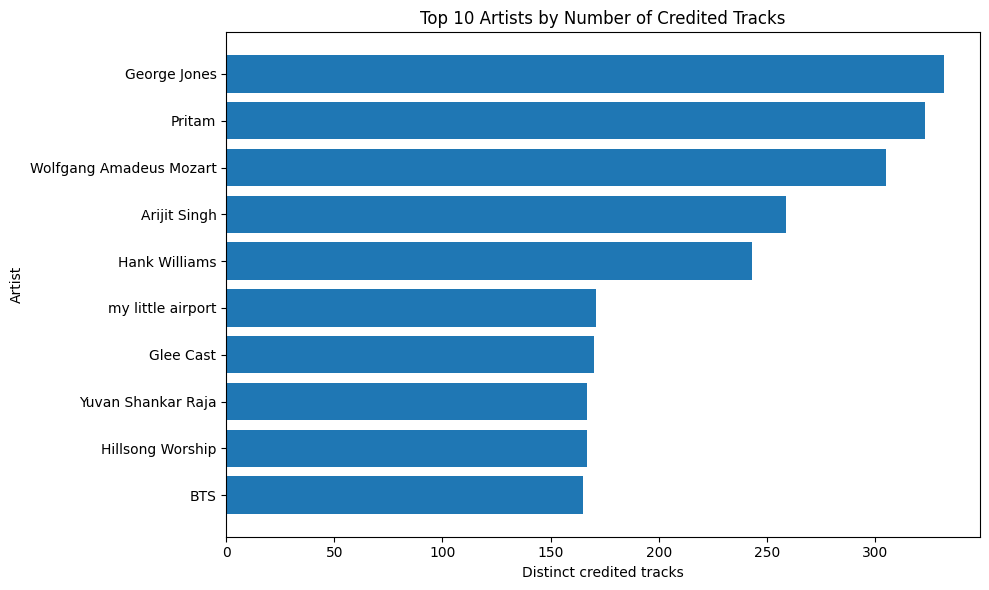

In [10]:
top_artists = artist_stats.head(10).sort_values("track_count", ascending=True)
if top_artists.empty:
    print("No usable artist records were found for the frequency chart.")
else:
    plt.figure(figsize=(10, 6))
    plt.barh(top_artists["artist"], top_artists["track_count"])
    plt.title("Top 10 Artists by Number of Credited Tracks")
    plt.xlabel("Distinct credited tracks")
    plt.ylabel("Artist")
    plt.tight_layout()
    plt.show()

## 9. Track-duration summary

The conversion is `duration_ms / 60,000 = duration_minutes`. Missing and non-positive durations are excluded from duration statistics. Long durations are retained in the statistics so unusual values are not silently hidden.

In [11]:
duration_summary = duration_data["duration_minutes"].describe().reindex(
    ["count", "mean", "50%", "std", "min", "25%", "75%", "max"]
).rename(index={
    "count": "Valid track records",
    "mean": "Mean duration (minutes)",
    "50%": "Median duration (minutes)",
    "std": "Standard deviation (minutes)",
    "min": "Minimum duration (minutes)",
    "25%": "25th percentile (minutes)",
    "75%": "75th percentile (minutes)",
    "max": "Maximum duration (minutes)",
})

duration_summary_df = duration_summary.to_frame(name="Value").round(2)
display(duration_summary_df)

long_duration_count = int((duration_data["duration_minutes"] > 15).sum())
long_duration_percent = (long_duration_count / len(duration_data) * 100) if len(duration_data) else 0
print(f"Records longer than 15 minutes: {long_duration_count:,} ({long_duration_percent:.2f}% of valid-duration records).")
print("These records remain in the summary above; the main histogram is capped at 15 minutes for readability.")

,Value
Valid track records,113549.00
Mean duration (minutes),3.80
Median duration (minutes),3.55
Standard deviation (minutes),1.77
Minimum duration (minutes),0.14
25th percentile (minutes),2.90
75th percentile (minutes),4.36
Maximum duration (minutes),87.29


Records longer than 15 minutes: 151 (0.13% of valid-duration records).
These records remain in the summary above; the main histogram is capped at 15 minutes for readability.


## 10. Visualization 2 — Track-duration distribution

To make the most common track lengths visible, the histogram shows valid durations up to 15 minutes. Longer records remain in the summary table and are counted above; they are not deleted from the dataset.

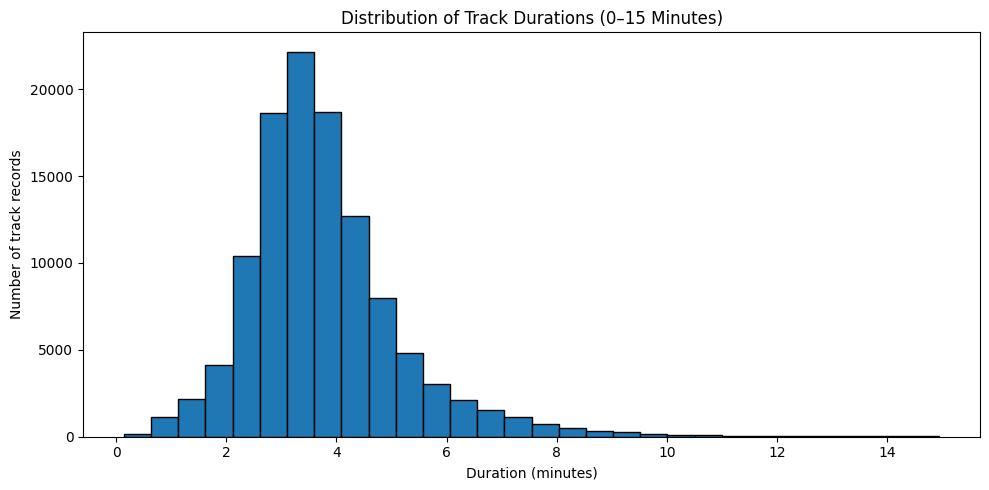

In [12]:
duration_plot_data = duration_data.loc[duration_data["duration_minutes"] <= 15, "duration_minutes"]
if duration_plot_data.empty:
    print("No valid duration values at or below 15 minutes are available to plot.")
else:
    plt.figure(figsize=(10, 5))
    plt.hist(duration_plot_data, bins=30, edgecolor="black")
    plt.title("Distribution of Track Durations (0–15 Minutes)")
    plt.xlabel("Duration (minutes)")
    plt.ylabel("Number of track records")
    plt.tight_layout()
    plt.show()

## 11. Visualization 3 — Duration box plot

The box plot uses the same 0–15 minute display window to keep the central distribution readable.

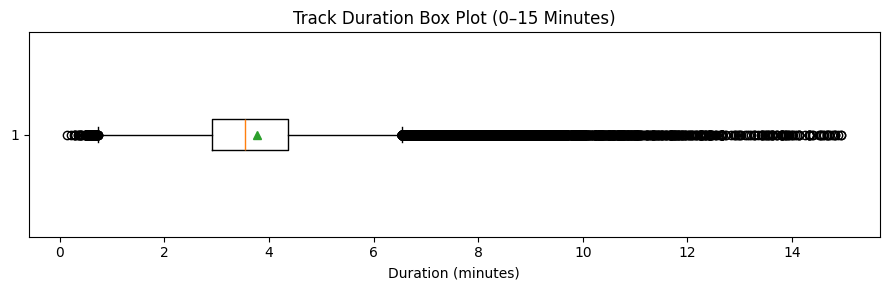

In [13]:
duration_plot_values = duration_data.loc[duration_data["duration_minutes"] <= 15, "duration_minutes"]
if duration_plot_values.empty:
    print("No valid values at or below 15 minutes are available for the box plot.")
else:
    plt.figure(figsize=(9, 3))
    plt.boxplot(duration_plot_values, vert=False, showmeans=True)
    plt.title("Track Duration Box Plot (0–15 Minutes)")
    plt.xlabel("Duration (minutes)")
    plt.tight_layout()
    plt.show()

## 12. Visualization 4 — Track count versus average popularity

It shows the 15 artists with the highest credited track counts. The chart is descriptive: it does not imply that having more tracks causes higher popularity, or that popularity measures artistic quality.

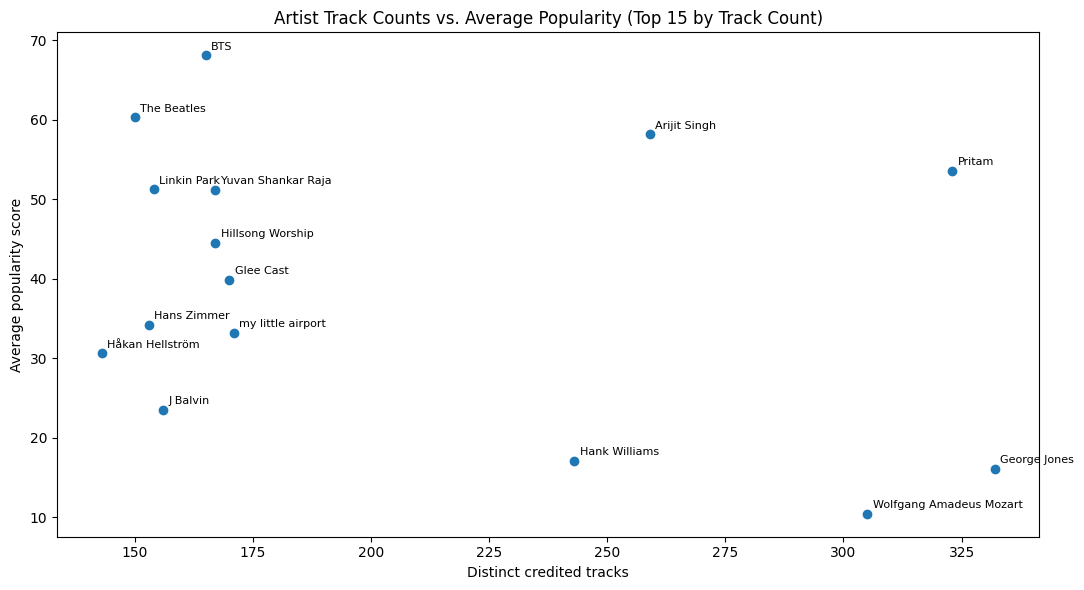

In [14]:
if "mean_popularity" not in artist_stats.columns:
    print("The dataset has no usable 'popularity' column, so this comparison is skipped.")
else:
    top_15_artist_patterns = artist_stats.head(15).dropna(subset=["mean_popularity"])
    if top_15_artist_patterns.empty:
        print("No valid popularity scores are available for artist-level comparison.")
    else:
        plt.figure(figsize=(11, 6))
        plt.scatter(top_15_artist_patterns["track_count"], top_15_artist_patterns["mean_popularity"])
        for _, row in top_15_artist_patterns.iterrows():
            plt.annotate(
                str(row["artist"]),
                (row["track_count"], row["mean_popularity"]),
                xytext=(4, 4), textcoords="offset points", fontsize=8
            )
        plt.title("Artist Track Counts vs. Average Popularity (Top 15 by Track Count)")
        plt.xlabel("Distinct credited tracks")
        plt.ylabel("Average popularity score")
        plt.tight_layout()
        plt.show()

## 13. Generating Markdown report from the actual results

this creates `artist_analysis.md` using the values calculated from your uploaded CSV and includes the top-artist table and duration summary.

In [15]:
def markdown_table(dataframe):
    """Convert a small DataFrame to a Markdown table without extra dependencies."""
    if dataframe.empty:
        return "_No data available._"
    display_df = dataframe.astype(object).where(pd.notna(dataframe), "—").astype(str)
    headers = list(display_df.columns)
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    for _, row in display_df.iterrows():
        values = [str(value).replace("|", "\\|").replace("\n", " ") for value in row.tolist()]
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)

# Formating the top-artist result table
report_artist_table = artist_stats.head(10).copy()
report_artist_table = report_artist_table.rename(columns={
    "artist": "Artist",
    "track_count": "Distinct credited tracks",
    "mean_popularity": "Mean popularity",
    "median_popularity": "Median popularity",
    "mean_duration_minutes": "Mean duration (min)",
})
for column in report_artist_table.columns:
    if column != "Artist":
        report_artist_table[column] = pd.to_numeric(report_artist_table[column], errors="coerce").round(2)

report_quality = quality_summary.copy()
report_quality["Count"] = report_quality["Count"].map(lambda value: f"{int(value):,}")
report_duration = duration_summary_df.reset_index().rename(columns={"index": "Measure", "Value": "Value (minutes unless noted)"})
report_duration["Value (minutes unless noted)"] = report_duration["Value (minutes unless noted)"].map(lambda value: f"{value:,.2f}" if pd.notna(value) else "—")

if not artist_stats.empty:
    leading_artist = str(artist_stats.iloc[0]["artist"])
    leading_count = int(artist_stats.iloc[0]["track_count"])
    leading_artist_sentence = f"The artist with the highest credited track count in this dataset is **{leading_artist}**, with **{leading_count:,} distinct credited track(s)** under the counting method used here."
else:
    leading_artist_sentence = "No valid artist credits were available for a frequency ranking."

median_duration = float(duration_data["duration_minutes"].median())
mean_duration = float(duration_data["duration_minutes"].mean())
if "popularity" in duration_data.columns:
    valid_pop = int(duration_data["popularity"].notna().sum())
    mean_pop_text = f"The mean popularity across valid-duration records with a numeric popularity value is **{duration_data['popularity'].mean():.2f}** (based on {valid_pop:,} records)."
else:
    mean_pop_text = "The dataset did not contain a usable `popularity` column, so artist-level popularity comparisons were skipped."

artist_names_with_multiple_credits = int((df["_artist_list"].map(len) > 1).sum())
track_id_note = (
    f"The file contains **{unique_track_ids:,} unique non-missing track IDs** and **{duplicate_track_id_rows:,} repeated track-ID row(s)** after exact duplicates were removed. Artist frequency deduplicates the same artist/track-ID pair."
    if unique_track_ids is not None
    else "No `track_id` column was available. Artist counts use row-level identifiers where a track ID is unavailable."
)

report_text = f"""# Artist and Track Characteristics Analysis

**Project:** The Anatomy of a Hit: Decoding Audio Features of Global Chart-Toppers
**Section:** Artists and Track Characteristics Analysis
**Dataset source:** [Spotify Tracks Dataset on Kaggle](https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset)
**Analyzed file:** `{source_file_name}`

## 1. Objective

This section investigates artist frequency, track-duration patterns, and artist-level differences in track counts and popularity. It also documents basic data-quality issues. The analysis is descriptive and does not use machine learning.

## 2. Research questions

1. Which artists have the most distinct credited tracks in the dataset?
2. What is the distribution of track duration?
3. How do track counts and average popularity compare among the most frequently credited artists?
4. How are multiple-artist tracks handled?
5. What duplicate or invalid values should be considered when interpreting the results?

## 3. Data preparation and counting rules

- Standardized column labels and removed typical exported index columns where present.
- Removed exact duplicate rows; repeated `track_id` values were reported rather than automatically deleting records.
- Converted `duration_ms` to numeric and calculated minutes by dividing by 60,000.
- Excluded missing or non-positive durations from duration statistics and plots, but retained long positive durations in the numerical summary.
- Parsed list-like artist credits when possible. Each named artist receives a credit for a multi-artist track. The same artist/track-ID pair is counted once when a usable `track_id` exists.
- Calculated artist-level popularity summaries only if the dataset includes a usable `popularity` column.

## 4. Data-quality checks

{markdown_table(report_quality)}

{track_id_note}

## 5. Track-duration summary

{markdown_table(report_duration)}

The duration histogram and box plot display records up to 15 minutes for readability. All valid positive duration values remain included in the duration summary above. There are **{long_duration_count:,}** valid-duration record(s) longer than 15 minutes ({long_duration_percent:.2f}%). These values were not silently removed.

## 6. Top artists

{markdown_table(report_artist_table)}

## 7. Key findings

- {leading_artist_sentence}
- The mean track duration is **{mean_duration:.2f} minutes** and the median track duration is **{median_duration:.2f} minutes** among records with valid positive durations.
- {mean_pop_text}
- **{artist_names_with_multiple_credits:,}** record(s) contain more than one parsed artist name. These collaborations were credited to each parsed artist rather than treated as a single unnamed combined artist.

Interpretation with reference to the generated charts: the artist-frequency chart compares distinct track credits, the duration histogram and box plot show the distribution within the 0–15 minute display window, and the scatter plot (when available) compares artist track counts with average popularity.

## 8. Limitations

- Popularity is a platform-specific score and may change over time; it is not a direct measure of artistic quality.
- Artist parsing depends on how names are encoded in the CSV. Plain ambiguous fields are not split on every comma to avoid incorrectly splitting names that contain commas.
- Repeated track IDs are flagged for transparency. Their presence does not, by itself, prove that the entire record is erroneous.
- Relationships in these descriptive charts do not establish causation.

## 9. Conclusion

This analysis describes which artists receive the most credited track entries in the dataset and summarizes the dataset's track-duration patterns. It compares artist-level track counts with average popularity when that field is available, while making collaboration-counting and data-quality decisions explicit. The numerical results above are calculated directly from the uploaded file and should be interpreted within the dataset's limitations.

## 10. Tools and reproducibility

- Python, Pandas, NumPy and Matplotlib
- Google Colab notebook: `notebooks/04_artist_analysis.ipynb`
- Dataset source: [Kaggle — Spotify Tracks Dataset](https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset)
"""

report_path = Path("artist_analysis.md")
report_path.write_text(report_text, encoding="utf-8")
print(f"Markdown report created: {report_path.resolve()}")
print("Open or download artist_analysis.md, then replace the starter file in your repository's docs/ folder with this generated report.")
display(Markdown("## Report generated successfully\nThe file `artist_analysis.md` now contains findings and summary tables from the dataset you uploaded."))

Markdown report created: /content/artist_analysis.md
Open or download artist_analysis.md, then replace the starter file in your repository's docs/ folder with this generated report.


## Report generated successfully
The file `artist_analysis.md` now contains findings and summary tables from the dataset you uploaded.

## 14. Downloading Markdown report

In [16]:
from google.colab import files
files.download("artist_analysis.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>